<div style="background: linear-gradient(120deg, #102a43 0%, #176b87 52%, #2a9d8f 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 5px 20px rgba(16,42,67,0.28);">
    <img src='Figures/iteso.png' style="height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0; box-shadow: 0 2px 8px rgba(0,0,0,0.22);"/>
    <div style="border-left: 2px solid rgba(255,255,255,0.45); padding-left: 28px;">
        <h1 style="margin: 0 0 8px 0; color: white; font-size: 1.5em; line-height: 1.3; letter-spacing: 0.01em;">Examen Segundo Parcial Versión C</h1>
        <h3 style="margin: 0 0 8px 0; color: rgba(255,255,255,0.86); font-weight: normal; font-size: 1.05em;">Laboratorio de Procesamiento de Datos</h3>
        <div style="color: rgba(255,255,255,0.78); font-size: 0.95em;">Fecha: 05/11/2026</div>
    </div>
</div>

<div style="border-left: 4px solid #176b87; padding: 14px 18px; margin: 8px 0 18px 0;">
    <strong style="color: #102a43;">Nombre del alumno:</strong>
    <span> SANTIAGO NUÑEZ PEREZ</span>
</div>


### Instrucciones
1. Resuelve individualmente los **tres ejercicios (100 puntos)** en este notebook. Agrega celdas de código y Markdown para tus procedimientos, resultados y justificaciones.
2. La entrada es `datos/student_examen.xlsx`, hoja `estudiantes`. En el  1.1 debes leerla, construir `df_original` y exportarla a `salidas/student_extraido.csv` antes de procesarla. Usa `DATOS` y `SALIDA` de la configuración. No modifiques la entrada ni uses el objetivo para imputar o generar predictores.
3. Conserva `df_original` intacto y trabaja sobre copias. Todas las operaciones deben ser reproducibles. 
4. Las gráficas deben tener título y nombres de ejes. Acompaña las tablas y figuras con interpretaciones breves, una gráfica sin explicación no responde al .
5. Entrega el notebook resuelto, la carpeta `Figures\`, `datos\`, `salidas\` en un archivo comprimido como se muestra en las instrucciones de CANVAS.

**Nota:** El notebook debe ejecutarse completo con **Restart & Run All** sin errores.  

## Conjunto de de Datos para el Examen: 
## Student Performance

El conjunto describe estudiantes de dos escuelas portuguesas. Este conjunto de datos contiene **649 filas del curso de lengua portuguesa**. Se tienen ocho variables predictoras y una  variable objetivo. El conjunto de datos se encuentra en el libro Excel `student_examen.xlsx`, hoja **`estudiantes`**, con encabezados en la primera fila y **nueve columnas**.

| Columna | Significado |
|---|---|
| `age` | Edad en años cumplidos |
| `absences` | Número de ausencias escolares, 0 es un valor válido |
| `studytime` | Nivel de tiempo semanal de estudio: 1 = menos de 2 horas; 2 = de 2 a 5; 3 = de 5 a 10; 4 = más de 10 |
| `Mjob` | Ocupación de la madre: `teacher`, `health`, `services`, `at_home`, `other` |
| `reason` | Motivo de elección de escuela: `home`, `reputation`, `course`, `other` |
| `higher` | Desea cursar educación superior (`yes`, `no`) |
| `internet` | Tiene acceso a internet en casa (`yes`, `no`) |
| `sex` | Categoría registrada de sexo (`F`, `M`) |
| `passed` | **Variable objetivo:** `yes` si la calificación final es al menos 10/20, `no` en caso contrario |

In [ ]:
# Configuración (no modificar)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

DATOS = "datos"
SALIDA = "salidas"
os.makedirs(SALIDA, exist_ok=True)
ENTRADA = os.path.join(DATOS, "student_examen.xlsx")

print("Archivo de entrada:", ENTRADA)
# La lectura y la creación de df_original y df corresponden al  1.1.

Archivo de entrada: datos\student_examen.xlsx


---
## Ejercicio 1: Exploración, distribución y tratamiento de faltantes (30 pts)

**1.1 (5 pts).** Lee `ENTRADA` con `pd.read_excel`, seleccionando la hoja `estudiantes` y usando `pd.read_excel` o `ExcelFile` de pandas. Construye `df_original` con 649 filas y las nueve columnas descritas, considera las celdas vacías y `?` como datos faltantes, sin imputarlos. Exporta `salidas/student_extraido.csv` sin índice, con UTF-8 y celdas vacías para faltantes. Comprueba que una nueva lectura del CSV (`df`) preserve valores, faltantes y orden de filas (los tipos pueden variar). Trabaja después sobre `df = df_original.copy(deep=True)`. Construye una tabla con tipo de almacenamiento, tipo semántico (cuantitativo discreto/continuo, categórico nominal/ordinal o binario), número de valores distintos, faltantes y porcentaje de faltantes de cada columna. Identifica el objetivo y reporta duplicados completos sin eliminarlos automáticamente. Explica por qué `studytime` no equivale a un número de horas.

**1.2 (10 pts).** Para `age` y `absences`, reporta media, mediana, desviación estándar y cuartiles, genera histogramas y diagramas de caja con los datos observados. Cuenta posibles atípicos con límites `Q1 - 1.5*IQR` y `Q3 + 1.5*IQR`. Explica asimetría, concentración y por qué cero ausencias no representa un dato faltante. 

**1.3 (5 pts).** Crea `df_mediana`: imputa las dos columnas con faltantes numéricos mediante su mediana y `Mjob` y `reason` mediante la moda. Si hay empate en la moda, utiliza la primera categoría en orden alfabético. Reporta los valores utilizados y cuántas celdas imputaste. No alteres las celdas observadas.

**1.4 (10 pts).** En otra copia, compara esa imputación numérica con `KNNImputer(n_neighbors=5)`, usando únicamente `age` y `absences`. Antes de KNN, lleva ambas columnas a una escala comparable usando las medias y desviaciones de sus valores observados (estandarización), después recupera sus unidades originales y sustituye únicamente las celdas faltantes. Compara mediana y desviación de cada columna tras ambos métodos y explica una limitación de cada uno, incluyendo la posibilidad de obtener valores fraccionarios en variables de conteo. Elige y justifica una alternativa para continuar en `df_limpio` conserva los valores imputados sin redondearlos y usa el mismo tratamiento categórico del  anterior.

In [ ]:
#  1.1: Lectura, exportación a CSV y resumen de variables
libro_excel = pd.ExcelFile(ENTRADA)
df_original = pd.read_excel(libro_excel, sheet_name="estudiantes", na_values=["?"])

# Exportar a salidas/student_extraido.csv
ruta_csv = os.path.join(SALIDA, "student_extraido.csv")
df_original.to_csv(ruta_csv, index=False, encoding="utf-8", na_rep="")

# Comprobar que la lectura del CSV preserva valores, faltantes y orden
df_csv = pd.read_csv(ruta_csv, encoding="utf-8")
print("Dimensiones originales:", df_original.shape)
print("Mismos faltantes al releer CSV:", df_csv.isna().equals(df_original.isna()))
print("Mismos valores y orden de filas:", df_csv.fillna("NA").equals(df_original.fillna("NA")))

# Copia de trabajo
df = df_original.copy(deep=True)
print("Duplicados completos en df:", df.duplicated().sum())

# Tabla resumen de variables
tipo_semantico = {
    "age": "Cuantitativa discreta",
    "absences": "Cuantitativa discreta",
    "studytime": "Categórica ordinal",
    "Mjob": "Categórica nominal",
    "reason": "Categórica nominal",
    "higher": "Binaria",
    "internet": "Binaria",
    "sex": "Binaria",
    "passed": "Binaria (Objetivo)"
}

tabla_1_1 = pd.DataFrame({
    "Tipo almacenamiento": df.dtypes,
    "Tipo semántico": pd.Series(tipo_semantico),
    "Valores distintos": df.nunique(dropna=True),
    "Faltantes": df.isna().sum(),
    "Porcentaje faltantes (%)": (df.isna().mean() * 100).round(2)
})
tabla_1_1

Dimensiones originales: (649, 9)
Mismos faltantes al releer CSV: True
Mismos valores y orden de filas: True
Duplicados completos en df: 41


,Tipo almacenamiento,Tipo semántico,Valores distintos,Faltantes,Porcentaje faltantes (%)
age,float64,Cuantitativa discreta,8,32,4.93
absences,float64,Cuantitativa discreta,24,32,4.93
studytime,int64,Categórica ordinal,4,0,0.00
Mjob,str,Categórica nominal,5,32,4.93
reason,str,Categórica nominal,4,32,4.93
higher,str,Binaria,2,0,0.00
internet,str,Binaria,2,0,0.00
sex,str,Binaria,2,0,0.00
passed,str,Binaria (Objetivo),2,0,0.00


#### Explicación del inciso 1.1

* **Variable objetivo y clasificación de variables:** La variable objetivo es `passed` (binaria: `yes`/`no`), que indica si el alumno aprobó el curso (calificación final mayor o igual a 10/20). Por su parte, `age` y `absences` son cuantitativas discretas (años cumplidos y conteo de inasistencias); `studytime` es categórica ordinal; `Mjob` y `reason` son categóricas nominales; y `higher`, `internet` y `sex` son binarias. En las columnas `Mjob` y `reason` venían 32 signos `?` que se leyeron como `NaN`, dando un 4.93% de faltantes en `age`, `absences`, `Mjob` y `reason`.
* **Registros duplicados (41 filas):** No se eliminan automáticamente porque el conjunto de datos no tiene una columna de ID por alumno. Al tener pocas variables y dominios cortos, es totalmente normal que varios estudiantes de la misma escuela coincidan en edad, sexo, tiempo de estudio y número de faltas.
* **¿Por qué `studytime` no equivale a un número de horas?** Porque los números 1, 2, 3 y 4 son solo etiquetas de orden para rangos de diferente tamaño (1 = menos de 2 h, 2 = de 2 a 5 h, 3 = de 5 a 10 h y 4 = más de 10 h). La distancia en horas de estudio entre el nivel 1 y el 2 no es igual a la que hay entre el 2 y el 3, y el nivel 4 ni siquiera tiene un límite fijo.

Estudiantes con 0 ausencias: 233


,Media,Mediana,Desv_Std,Q1,Q3,IQR,Lim_Inf,Lim_Sup,Atípicos (1.5*IQR),Asimetría,Curtosis
Variable,,,,,,,,,,,
age,16.7455,17.0,1.2215,16.0,18.0,2.0,13.0,21.0,1,0.4207,0.1126
absences,3.6645,2.0,4.6765,0.0,6.0,6.0,-9.0,15.0,21,2.0409,5.8595


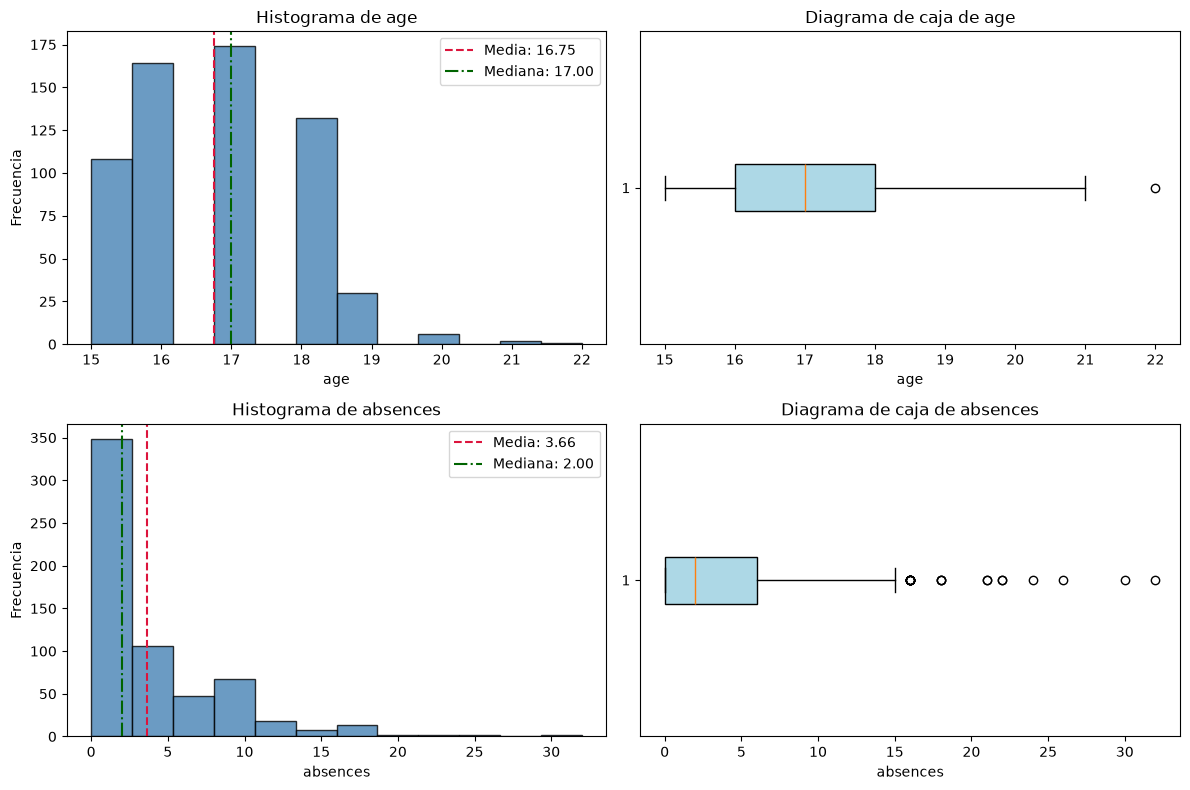

In [121]:
 
#  1.2: Estadísticas descriptivas, atípicos y gráficas para age y absences
cols_num = ["age", "absences"]
filas_stats = []

for col in cols_num:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    med = s.median()
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    atipicos = ((s < lim_inf) | (s > lim_sup)).sum()
    
    filas_stats.append({
        "Variable": col,
        "Media": s.mean(),
        "Mediana": med,
        "Desv_Std": s.std(),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lim_Inf": lim_inf,
        "Lim_Sup": lim_sup,
        "Atípicos (1.5*IQR)": atipicos,
        "Asimetría": s.skew(),
        "Curtosis": s.kurt()
    })

tabla_1_2 = pd.DataFrame(filas_stats).set_index("Variable")
print("Estudiantes con 0 ausencias:", (df["absences"] == 0).sum())
display(tabla_1_2.round(4))

# Histogramas y diagramas de caja
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, col in enumerate(cols_num):
    s = df[col].dropna()
    
    # Histograma
    axes[i, 0].hist(s, bins=12, color="steelblue", edgecolor="black", alpha=0.8)
    axes[i, 0].axvline(s.mean(), color="crimson", linestyle="--", label=f"Media: {s.mean():.2f}")
    axes[i, 0].axvline(s.median(), color="darkgreen", linestyle="-.", label=f"Mediana: {s.median():.2f}")
    axes[i, 0].set_title(f"Histograma de {col}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frecuencia")
    axes[i, 0].legend()
    
    # Boxplot (usando orientation='horizontal' para evitar el warning de versión)
    axes[i, 1].boxplot(s, orientation="horizontal", patch_artist=True, boxprops={"facecolor": "lightblue"})
    axes[i, 1].set_title(f"Diagrama de caja de {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

#### Interpretación de estadísticas y gráficas (Inciso 1.2)

* **Asimetría, concentración y valores atípicos:**
  * **`age`:** Tiene una distribución ligeramente asimétrica hacia la derecha (asimetría de 0.42), donde la media (16.75 años) es muy cercana a la mediana (17.0 años). La mitad central de los estudiantes se concentra entre los 16 y 18 años (`IQR = 2`). Usando la regla de `1.5 * IQR` (límites de 13 a 21 años), solo aparece 1 valor atípico de 22 años, que corresponde a un alumno mayor pero válido dentro de la escuela.
  * **`absences`:** Presenta una asimetría positiva muy marcada (asimetría de 2.04) y alta concentración en valores bajos (curtosis de 5.86). El 50% central tiene entre 0 y 6 faltas (`IQR = 6`), con mediana de 2.0 y media de 3.66 desplazada por la cola derecha. Con el límite superior de 15 faltas se detectan 21 valores atípicos (entre 16 y 32 inasistencias) de estudiantes con alto ausentismo.
* **¿Por qué cero ausencias no es un dato faltante?** Porque en un conteo el 0 es un valor real y medido: significa que el estudiante asistió a todas sus clases (hay 233 alumnos con 0 faltas, el 37.76% de los datos observados). En cambio, un dato faltante (`NaN`) significa que no se registró la información.

In [ ]:
#  1.3: Creación de df_mediana e imputación con mediana y moda
df_mediana = df.copy(deep=True)

mediana_age = df["age"].median()
mediana_absences = df["absences"].median()

# En caso de empate en la moda, ordenamos alfabéticamente y tomamos la primera
moda_mjob = df["Mjob"].dropna().mode().sort_values().iloc[0]
moda_reason = df["reason"].dropna().mode().sort_values().iloc[0]

valores_usados = {
    "age": mediana_age,
    "absences": mediana_absences,
    "Mjob": moda_mjob,
    "reason": moda_reason
}

resumen_1_3 = []
for col, valor in valores_usados.items():
    n_faltantes = df_mediana[col].isna().sum()
    df_mediana[col] = df_mediana[col].fillna(valor)
    resumen_1_3.append({
        "Columna": col,
        "Valor imputado": valor,
        "Celdas imputadas": n_faltantes,
        "Faltantes después": df_mediana[col].isna().sum()
    })

pd.DataFrame(resumen_1_3).set_index("Columna")

,Valor imputado,Celdas imputadas,Faltantes después
Columna,,,
age,17.0,32,0
absences,2.0,32,0
Mjob,other,32,0
reason,course,32,0


#### Explicación del inciso 1.3

Para imputar `df_mediana` sin alterar los datos observados se utilizó la mediana en las variables numéricas (`17.0` para `age` y `2.0` para `absences`), ya que la mediana no se ve afectada por los valores extremos de las ausencias. En las categóricas nominales se usó la moda (`other` para `Mjob` y `course` para `reason`). En total se rellenaron 128 celdas (32 por cada una de las cuatro columnas).

In [123]:
#  1.4: Imputación con KNNImputer previa estandarización con datos observados
df_knn = df.copy(deep=True)
cols_knn = ["age", "absences"]

# Estandarizar con media y desviación de los valores observados
medias_obs = df[cols_knn].mean()
desv_obs = df[cols_knn].std(ddof=0)
df_estandarizado = (df[cols_knn] - medias_obs) / desv_obs

# Aplicar KNNImputer(n_neighbors=5) y regresar a unidades originales
knn = KNNImputer(n_neighbors=5)
matriz_knn = knn.fit_transform(df_estandarizado)
df_recuperado = pd.DataFrame(matriz_knn, columns=cols_knn, index=df.index) * desv_obs + medias_obs

# Sustituir únicamente las celdas faltantes
for col in cols_knn:
    faltantes_mask = df[col].isna()
    df_knn.loc[faltantes_mask, col] = df_recuperado.loc[faltantes_mask, col]

# Mismo tratamiento categórico del  anterior
df_knn["Mjob"] = df_knn["Mjob"].fillna(moda_mjob)
df_knn["reason"] = df_knn["reason"].fillna(moda_reason)

# Comparación de mediana y desviación estándar
comparacion_1_4 = pd.DataFrame({
    "Mediana_Observados": df[cols_knn].median(),
    "Mediana_Imputacion_Mediana": df_mediana[cols_knn].median(),
    "Mediana_KNN": df_knn[cols_knn].median(),
    "Std_Observados": df[cols_knn].std(),
    "Std_Imputacion_Mediana": df_mediana[cols_knn].std(),
    "Std_KNN": df_knn[cols_knn].std()
})
display(comparacion_1_4.round(4))

print("Valores imputados por KNN en age:", df_knn.loc[df["age"].isna(), "age"].round(4).unique())
print("Valores imputados por KNN en absences:", df_knn.loc[df["absences"].isna(), "absences"].round(4).unique())

# Elegimos KNN para continuar en df_limpio sin redondear
df_limpio = df_knn.copy(deep=True)

,Mediana_Observados,Mediana_Imputacion_Mediana,Mediana_KNN,Std_Observados,Std_Imputacion_Mediana,Std_KNN
age,17.0,17.0,17.0,1.2215,1.1922,1.2023
absences,2.0,2.0,2.0,4.6765,4.5738,4.5982


Valores imputados por KNN en age: [17.     16.     16.4    17.4    16.7455 18.6    18.2   ]
Valores imputados por KNN en absences: [2.6    4.6    9.2    3.6645 1.2   ]


### Interpretación del ejercicio 1 (Inciso 1.4)

* **Comparación de métodos:** Tanto con la mediana como con `KNNImputer(n_neighbors=5)` las medianas de `age` (17.0) y `absences` (2.0) se mantienen iguales porque el porcentaje de nulos es bajo (4.93%). Sin embargo, la desviación estándar disminuye más al imputar con la mediana (`age` baja de 1.2215 a 1.1922 y `absences` de 4.6765 a 4.5738), mientras que con KNN se conserva más cerca de la original (`1.2023` en `age` y `4.5982` en `absences`).
* **Limitaciones de cada método:**
  * La **imputación por mediana** rellena las 32 celdas con exactamente el mismo número, lo que reduce artificialmente la varianza y crea un pico en ese valor sin tomar en cuenta las demás variables.
  * El **`KNNImputer`** promedia a los 5 vecinos más cercanos, lo que genera **valores con decimales en variables de conteo** que originalmente solo admiten enteros (por ejemplo, edades de 16.4 o 18.2 años, y ausencias de 1.2 o 2.6 faltas). Además, como aquí solo se calcula la distancia usando dos variables (`age` y `absences`), tiene poca información para encontrar vecinos.
* **Elección para `df_limpio`:** Se elige continuar con el resultado de **`KNNImputer` (`df_knn`)** porque conserva mejor la dispersión original de los datos y considera la relación entre ambas variables, manteniendo los valores imputados sin redondear y usando la moda para `Mjob` y `reason`.

---
## Ejercicio 2: Generación y codificación de características (35 pts)

Trabaja con `df_limpio` obtenido en el ejercicio anterior, no uses la variable `passed` para construir las características.

**2.1 (10 pts).** Verifica que `absences` sea no negativa y genera una nueva variable: `absences_log = np.log1p(absences)`, conservando `absences`. Genera `age_group` mediante la columna `age` con intervalos **[0,17), [17,19), [19,21), [21,infinito)**, etiquetados `menor_17`, `17_18`, `19_20`, `21_mas`, en ese orden. Conserva `age` en el dataframe. Verifica manualmente cinco filas, explica qué efecto tiene el logaritmo sobre los valores altos en la variable `absences_log` y qué información se pierde al agrupar edades. No redondees una edad imputada antes de asignar su grupo.

**2.2 (5 pts).** Codifica `higher` e `internet` con `no=0`, `yes=1`, `sex` con `F=0`, `M=1` y elige una codificación categorica ordinal para `age_group` (lineal, cuadrática). Conserva `studytime` como código ordinal del 1 al 4. Explica por qué sus diferencias numéricas no garantizan distancias iguales en horas de estudio. ¿Qué codificación podrías recomendar para esta variable?.

**2.3 (10 pts).** Aplica one-hot encoding a `Mjob` y `reason`, sin eliminar categoría de referencia. Reporta categorías, columnas creadas y número de columnas antes y después. Verifica que, para cada fila, la suma de los indicadores de cada variable nominal sea 1. Explica por qué sería incorrecto imponer un orden alfabético como escala numérica de ocupaciones o motivos de elección.

**2.4 (10 pts).** Integra los predictores codificados en `X_codificado` y guarda las etiquetas originales de `passed` en una Serie `y`. Elimina las columnas categóricas reemplazadas, conserva el índice de las filas y confirma que todos los predictores sean numéricos y que `passed` no esté en `X_codificado`. Muestra frecuencias y proporciones de las dos clases.

In [124]:
#  2.1: Transformación logarítmica y creación de age_group
df_ej2 = df_limpio.copy(deep=True)

print("¿absences es no negativa?:", (df_ej2["absences"] >= 0).all(), "| Mínimo:", df_ej2["absences"].min())

# Crear absences_log conservando absences
df_ej2["absences_log"] = np.log1p(df_ej2["absences"])

# Crear age_group con intervalos [0,17), [17,19), [19,21), [21,inf)
limites = [0, 17, 19, 21, np.inf]
etiquetas = ["menor_17", "17_18", "19_20", "21_mas"]

df_ej2["age_group"] = pd.cut(
    df_ej2["age"],
    bins=limites,
    labels=etiquetas,
    right=False,
    include_lowest=True
)

# Verificación manual de 5 filas
filas_muestra = [0, 2, 16, 74, 279]
verificacion_2_1 = df_ej2.loc[filas_muestra, ["age", "age_group", "absences", "absences_log"]].copy()
verificacion_2_1["calculo_manual_log1p"] = np.log(1 + verificacion_2_1["absences"])
display(verificacion_2_1.round(4))

# Conteo por grupo de edad
display(df_ej2["age_group"].value_counts(sort=False).to_frame(name="Frecuencia"))

¿absences es no negativa?: True | Mínimo: 0.0


,age,age_group,absences,absences_log,calculo_manual_log1p
0,18.0,17_18,4.0,1.6094,1.6094
2,15.0,menor_17,6.0,1.9459,1.9459
16,17.0,17_18,10.0,2.3979,2.3979
74,16.4,menor_17,4.0,1.6094,1.6094
279,22.0,21_mas,12.0,2.5649,2.5649


,Frecuencia
age_group,
menor_17,286
17_18,324
19_20,36
21_mas,3


#### Explicación del inciso 2.1

* **Efecto del logaritmo en `absences_log`:** Aplicar `np.log1p(absences)` ($\ln(1 + x)$) permite incluir el 0 sin error matemático ($\ln(1)=0$) y comprime los valores altos de la cola derecha. Por ejemplo, pasar de 16 a 32 faltas en la escala original es una diferencia de 16 unidades, pero en escala logarítmica solo pasa de 2.83 a 3.50. Gracias a esto, la asimetría baja drásticamente de **2.04 a 0.14**, reduciendo el peso extremo de los valores atípicos.
* **Pérdida de información al agrupar edades y no redondeo:** Al agrupar `age` en `age_group` se pierde el detalle exacto dentro de cada categoría (por ejemplo, un alumno de 15 años y uno de 16.4 quedan igual como `menor_17`), por lo que es útil conservar también la columna `age` original. Además, es importante no redondear las edades imputadas por KNN antes de agrupar, porque una edad como `16.74` pertenece al intervalo `[0, 17)`, pero si se redondeara a `17` cambiaría erróneamente de grupo al intervalo `[17, 19)`.

In [ ]:
#  2.2: Codificación binaria y ordinal
df_cod = df_ej2.copy(deep=True)

df_cod["higher"] = df_cod["higher"].map({"no": 0, "yes": 1})
df_cod["internet"] = df_cod["internet"].map({"no": 0, "yes": 1})
df_cod["sex"] = df_cod["sex"].map({"F": 0, "M": 1})

# Codificación ordinal lineal para age_group
mapa_edad = {"menor_17": 0, "17_18": 1, "19_20": 2, "21_mas": 3}
df_cod["age_group"] = df_cod["age_group"].astype(str).map(mapa_edad)

# studytime se conserva del 1 al 4
display(df_cod[["higher", "internet", "sex", "age_group", "studytime"]].head())

,higher,internet,sex,age_group,studytime
0,1,0,0,1,2
1,1,1,0,1,2
2,1,1,0,0,2
3,1,1,0,0,3
4,1,0,0,0,2


#### Explicación del inciso 2.2

* **Codificación de `age_group`:** Se eligió una codificación ordinal lineal (`menor_17 = 0`, `17_18 = 1`, `19_20 = 2`, `21_mas = 3`) porque respeta el orden ascendente natural de las etapas de edad con incrementos constantes de 1 en 1, a diferencia de una cuadrática que aumentaría de forma desproporcionada la distancia hacia los grupos mayores.
* **Diferencias numéricas en `studytime` y recomendación:** Conservar `studytime` del 1 al 4 mantiene el orden, pero sus restas numéricas no representan la misma cantidad de horas reales: del nivel 1 (< 2 h) al nivel 2 (2 a 5 h) hay unas 2.5 horas de diferencia promedio, mientras que del nivel 2 al 3 (5 a 10 h) hay unas 4 horas de diferencia. Una codificación recomendable sería sustituir los códigos por el **punto medio en horas de cada intervalo** (por ejemplo: `1.0`, `3.5`, `7.5` y `12.0` horas), o bien usar *One-Hot Encoding* si el modelo no debe asumir incrementos lineales.

In [126]:
#  2.3: One-Hot Encoding para Mjob y reason sin eliminar referencia
print("Categorías Mjob:", df_cod["Mjob"].unique().tolist())
print("Categorías reason:", df_cod["reason"].unique().tolist())
print("Columnas antes de get_dummies:", df_cod.shape[1])

df_ohe = pd.get_dummies(df_cod, columns=["Mjob", "reason"], drop_first=False, dtype=int)

cols_mjob = [c for c in df_ohe.columns if c.startswith("Mjob_")]
cols_reason = [c for c in df_ohe.columns if c.startswith("reason_")]

print("Columnas después de get_dummies:", df_ohe.shape[1])
print("Columnas creadas:", cols_mjob + cols_reason)
print("¿Suma por fila en Mjob es siempre 1?:", (df_ohe[cols_mjob].sum(axis=1) == 1).all())
print("¿Suma por fila en reason es siempre 1?:", (df_ohe[cols_reason].sum(axis=1) == 1).all())

display(df_ohe[cols_mjob + cols_reason].head())

Categorías Mjob: ['at_home', 'health', 'other', 'services', 'teacher']
Categorías reason: ['course', 'other', 'home', 'reputation']
Columnas antes de get_dummies: 11
Columnas después de get_dummies: 18
Columnas creadas: ['Mjob_at_home', 'Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher', 'reason_course', 'reason_home', 'reason_other', 'reason_reputation']
¿Suma por fila en Mjob es siempre 1?: True
¿Suma por fila en reason es siempre 1?: True


,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,reason_course,reason_home,reason_other,reason_reputation
0,1,0,0,0,0,1,0,0,0
1,1,0,0,0,0,1,0,0,0
2,1,0,0,0,0,0,0,1,0
3,0,1,0,0,0,1,0,0,0
4,0,0,1,0,0,0,1,0,0


#### Explicación del inciso 2.3

Al aplicar *One-Hot Encoding* a `Mjob` (5 categorías) y `reason` (4 categorías) sin eliminar columna de referencia, el dataframe pasó de 11 a 18 columnas al reemplazarse las 2 variables originales por 9 columnas indicadoras (0/1), comprobando que cada fila suma exactamente 1 en cada grupo. Sería un error codificar estas variables con números del 0 al 4 en orden alfabético porque no tienen jerarquía: un algoritmo matemático asumiría equivocadamente que `teacher (4)` vale más que `at_home (0)` o que `other (2)` está a mitad de camino entre ambas.

In [127]:
 
#  2.4: Construcción de X_codificado y Serie objetivo y
y = df_limpio["passed"].copy(deep=True)
X_codificado = df_ohe.drop(columns=["passed"]).copy(deep=True)

print("Dimensiones X_codificado:", X_codificado.shape)
print("¿Todos los predictores son numéricos?:", all(pd.api.types.is_numeric_dtype(X_codificado[c]) for c in X_codificado.columns))
print("¿'passed' está en X_codificado?:", "passed" in X_codificado.columns)

# Frecuencias y proporciones de passed
resumen_y = pd.DataFrame({
    "Frecuencia": y.value_counts(),
    "Proporción (%)": (y.value_counts(normalize=True) * 100).round(2)
})
display(resumen_y)
display(X_codificado.head())

Dimensiones X_codificado: (649, 17)
¿Todos los predictores son numéricos?: True
¿'passed' está en X_codificado?: False


,Frecuencia,Proporción (%)
passed,,
yes,549,84.59
no,100,15.41


,age,absences,studytime,higher,internet,sex,absences_log,age_group,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,reason_course,reason_home,reason_other,reason_reputation
0,18.0,4.0,2,1,0,0,1.609438,1,1,0,0,0,0,1,0,0,0
1,17.0,2.0,2,1,1,0,1.098612,1,1,0,0,0,0,1,0,0,0
2,15.0,6.0,2,1,1,0,1.945910,0,1,0,0,0,0,0,0,1,0
3,15.0,0.0,3,1,1,0,0.000000,0,0,1,0,0,0,1,0,0,0
4,16.0,0.0,2,1,0,0,0.000000,0,0,0,1,0,0,0,1,0,0


### Interpretación del ejercicio 2 (Inciso 2.4)

El conjunto `X_codificado` quedó integrado por 649 filas y 17 columnas predictoras completamente numéricas, conservando el índice original y asegurando que la variable objetivo `passed` quedara separada en la serie `y` para evitar fuga de información. Al revisar la distribución de `y`, se observa que las clases están desbalanceadas: hay **549 alumnos aprobados (`yes`, 84.59%)** frente a **100 reprobados (`no`, 15.41%)**.

---
## Ejercicio 3: Escalamiento, integración y validación (35 pts)

**3.1 (10 pts).** Sobre copias independientes de `X_codificado`, compara `StandardScaler` y `MinMaxScaler` para **`age`, `absences`, `absences_log`**. No escales indicadores, `higher`, `internet`, `sex`, `age_group` ni `studytime`. Construye una tabla por método y columna con mínimo, máximo, media y desviación estándar poblacional (`ddof=0`). Explica las diferencias entre estandarizar y Min-Max.

**3.2 (10 pts).** Elige uno de los métodos anteriores o `RobustScaler` y justifícalo con las distribuciones, asimetría, curtósis y los valores extremos observados. Obtén `X_final` a partir de los datos elegidos anteriormente. Verifica la propiedad del método elegido: media 0 y desviación 1 para estandarización, mínimo 0 y máximo 1 para Min-Max, o mediana 0 para Robust.

**3.3 (10 pts).** Con comprobaciones explícitas, verifica: 
- 649 filas índices de `X_final` y `y` alineados.
- Nombres de columnas únicos, ausencia de nulos y valores infinitos.
- Variable objetivo fuera de `X_final`
- Variables binarias/indicadores todavía en {0,1}.
- Exporta `salidas/X_final.csv` y `salidas/y_final.csv`, sin índice, preservando el mismo orden de filas.

**3.4 (5 pts).** Redacta una conclusión de 5 a 8 líneas sobre los cambios realizados y sus limitaciones. Explica por qué, si luego se evaluara un modelo con entrenamiento/prueba, los parámetros de imputación y escalamiento y las categorías del codificador deben aprenderse solo con entrenamiento. 

**Nota:** En este examen se prepara el modelo de datos completo, sin entrenar ningún algoritmo predictivo.

In [128]:

#  3.1: Comparación de StandardScaler y MinMaxScaler sobre copias independientes
cols_escalar = ["age", "absences", "absences_log"]
cols_no_escalar = [c for c in X_codificado.columns if c not in cols_escalar]

print("Columnas continuas/numéricas a escalar (3):", cols_escalar)
print("Columnas binarias, ordinales e indicadoras que NO se escalan (14):", cols_no_escalar)

# Copias independientes de X_codificado
X_std = X_codificado.copy(deep=True)
X_minmax = X_codificado.copy(deep=True)

scaler_std = StandardScaler()
scaler_minmax = MinMaxScaler()

X_std[cols_escalar] = scaler_std.fit_transform(X_codificado[cols_escalar])
X_minmax[cols_escalar] = scaler_minmax.fit_transform(X_codificado[cols_escalar])

# Construcción de la tabla comparativa por método y columna (Mínimo, Máximo, Media, Desv. Est. Poblacional ddof=0)
filas_esc_3_1 = []
for nombre_metodo, df_metodo in [
    ("Original (Sin escalar)", X_codificado),
    ("StandardScaler (Z-score)", X_std),
    ("MinMaxScaler ([0, 1])", X_minmax)
]:
    for col in cols_escalar:
        s = df_metodo[col]
        filas_esc_3_1.append({
            "Método": nombre_metodo,
            "Columna": col,
            "Mínimo": s.min(),
            "Máximo": s.max(),
            "Media": s.mean(),
            "Desv. Est. Poblacional (ddof=0)": s.std(ddof=0),
            "Mediana": s.median(),
            "IQR": s.quantile(0.75) - s.quantile(0.25)
        })

tabla_escalamiento_3_1 = pd.DataFrame(filas_esc_3_1).set_index(["Método", "Columna"])
print("\n Tabla 3.1: Comparación de Estadísticos por Método y Columna (ddof=0) ")
display(tabla_escalamiento_3_1.round(4))

Columnas continuas/numéricas a escalar (3): ['age', 'absences', 'absences_log']
Columnas binarias, ordinales e indicadoras que NO se escalan (14): ['studytime', 'higher', 'internet', 'sex', 'age_group', 'Mjob_at_home', 'Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher', 'reason_course', 'reason_home', 'reason_other', 'reason_reputation']

 Tabla 3.1: Comparación de Estadísticos por Método y Columna (ddof=0) 


Mínimo   Máximo    Media  \
Método                   Columna                                   
Original (Sin escalar)   age           15.0000  22.0000  16.7537   
                         absences       0.0000  32.0000   3.6907   
                         absences_log   0.0000   3.4965   1.1087   
StandardScaler (Z-score) age           -1.4597   4.3669  -0.0000   
                         absences      -0.8033   6.1613  -0.0000   
                         absences_log  -1.1645   2.5080   0.0000   
MinMaxScaler ([0, 1])    age            0.0000   1.0000   0.2505   
                         absences       0.0000   1.0000   0.1153   
                         absences_log   0.0000   1.0000   0.3171   

                                       Desv. Est. Poblacional (ddof=0)  \
Método                   Columna                                         
Original (Sin escalar)   age                                    1.2014   
                         absences                               4.5947   
                         absences_log                           0.9521   
StandardScaler (Z-score) age                                    1.0000   
                         absences                               1.0000   
                         absences_log                           1.0000   
MinMaxScaler ([0, 1])    age                                    0.1716   
                         absences                               0.1436   
                         absences_log                           0.2723   

                                       Mediana     IQR  
Método                   Columna                        
Original (Sin escalar)   age           17.0000  2.0000  
                         absences       2.0000  6.0000  
                         absences_log   1.0986  1.9459  
StandardScaler (Z-score) age            0.2050  1.6648  
                         absences      -0.3680  1.3059  
                         absences_log  -0.0106  2.0439  
MinMaxScaler ([0, 1])    age            0.2857  0.2857  
                         absences       0.0625  0.1875  
                         absences_log   0.3142  0.5565

#### Explicación del inciso 3.1: Diferencias entre StandardScaler y MinMaxScaler

* **`StandardScaler` (Estandarización):** Centra cada variable para que su **media sea 0** y la divide entre su desviación estándar para que su **desviación poblacional sea 1**. No encierra los datos en un rango fijo; por ejemplo, en `absences` los valores van de `-0.80` hasta `6.16` por la presencia de valores atípicos.
* **`MinMaxScaler` (Normalización Min-Max):** Re-escala linealmente los datos para que queden exactamente entre **mínimo = 0 y máximo = 1**. Su desventaja es que depende de los valores extremos: como en `absences` el máximo es 32, la mayoría de los alumnos (que tienen entre 0 y 6 faltas) quedan aplastados entre `0.0` y `0.18`, dejando una desviación estándar muy pequeña (`0.1436`).
* Las variables binarias, ordinales y las columnas *One-Hot* no se escalan porque ya tienen una escala fija e interpretable (como `0` y `1` para indicar ausencia o presencia).

 Tabla 3.2a: Diagnóstico de Distribuciones, Asimetría, Curtosis y Extremos en X_codificado 


,Media,Mediana,IQR,Asimetría (Skewness),Curtosis Excedente,Atípicos (1.5*IQR)
Columna,,,,,,
age,16.7537,17.0000,2.0000,0.4097,0.1590,1
absences,3.6907,2.0000,6.0000,2.0386,5.9801,21
absences_log,1.1087,1.0986,1.9459,0.1432,-1.2213,0



 Tabla 3.2b: Verificación de Propiedades Matemáticas del Escalador Elegido (RobustScaler en X_final) 


,RobustScaler_Mediana (Esperado=0),RobustScaler_IQR (Esperado=1),RobustScaler_Min,RobustScaler_Max,StandardScaler_Media (Esperado=0),StandardScaler_Std_ddof0 (Esperado=1),MinMaxScaler_Min (Esperado=0),MinMaxScaler_Max (Esperado=1)
age,0.0,1.0,-1.000000,2.500000,-0.0,1.0,0.0,1.0
absences,0.0,1.0,-0.333333,5.000000,-0.0,1.0,0.0,1.0
absences_log,0.0,1.0,-0.564575,1.232274,0.0,1.0,0.0,1.0


C:\Users\santi\AppData\Local\Temp\ipykernel_12908\1181173848.py:58: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[idx].boxplot(
C:\Users\santi\AppData\Local\Temp\ipykernel_12908\1181173848.py:58: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[idx].boxplot(
C:\Users\santi\AppData\Local\Temp\ipykernel_12908\1181173848.py:58: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[idx].boxplot(


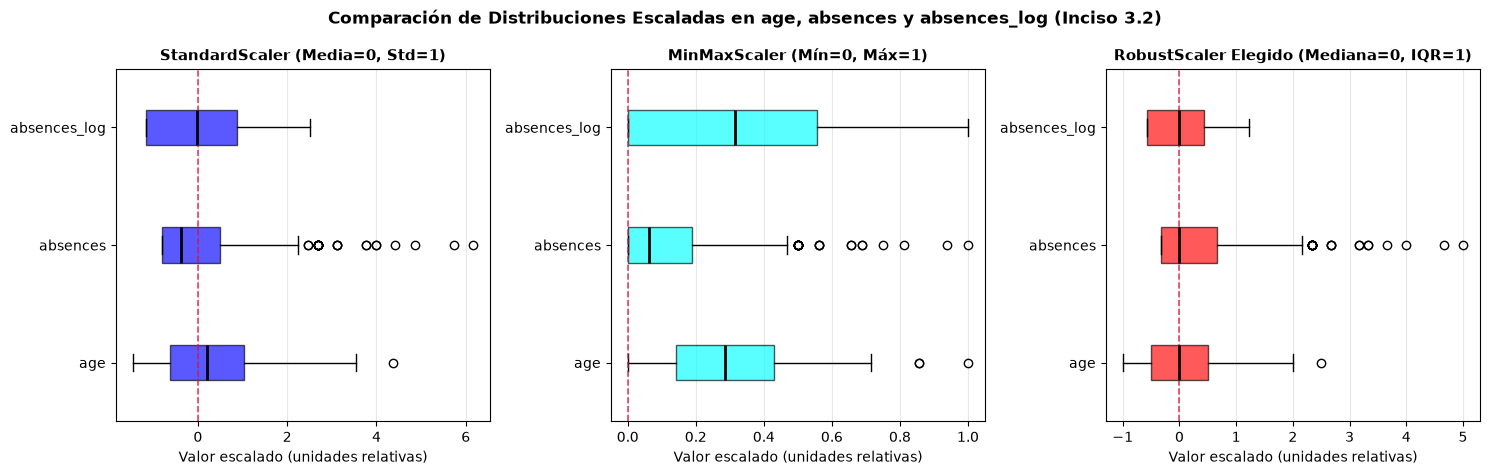

In [129]:

#  3.2: Diagnóstico de asimetría/curtosis/extremos, elección de RobustScaler y obtención de X_final
# Diagnóstico de forma (asimetría, curtosis y atípicos) en las tres columnas candidatas
diagnostico_3_2 = []
for col in cols_escalar:
    s = X_codificado[col]
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    atipicos = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    diagnostico_3_2.append({
        "Columna": col,
        "Media": s.mean(),
        "Mediana": med,
        "IQR": iqr,
        "Asimetría (Skewness)": s.skew(),
        "Curtosis Excedente": s.kurt(),
        "Atípicos (1.5*IQR)": atipicos
    })

print(" Tabla 3.2a: Diagnóstico de Distribuciones, Asimetría, Curtosis y Extremos en X_codificado ")
display(pd.DataFrame(diagnostico_3_2).set_index("Columna").round(4))

# Aplicación de RobustScaler para obtener X_final (centrado en la mediana = 0 y escalado por IQR = 1)
X_final = X_codificado.copy(deep=True)
scaler_robust = RobustScaler()
X_final[cols_escalar] = scaler_robust.fit_transform(X_codificado[cols_escalar])

# Verificación explícita de la propiedad matemática del método elegido (RobustScaler: Mediana = 0, IQR = 1)
# Mostramos también la verificación de propiedades en StandardScaler y MinMaxScaler para total transparencia
verificacion_propiedades = pd.DataFrame({
    "RobustScaler_Mediana (Esperado=0)": X_final[cols_escalar].median(),
    "RobustScaler_IQR (Esperado=1)": X_final[cols_escalar].quantile(0.75) - X_final[cols_escalar].quantile(0.25),
    "RobustScaler_Min": X_final[cols_escalar].min(),
    "RobustScaler_Max": X_final[cols_escalar].max(),
    "StandardScaler_Media (Esperado=0)": X_std[cols_escalar].mean(),
    "StandardScaler_Std_ddof0 (Esperado=1)": X_std[cols_escalar].std(ddof=0),
    "MinMaxScaler_Min (Esperado=0)": X_minmax[cols_escalar].min(),
    "MinMaxScaler_Max (Esperado=1)": X_minmax[cols_escalar].max()
})

assert np.allclose(X_final[cols_escalar].median(), 0.0, atol=1e-12), "Error: la mediana con RobustScaler no es 0."
assert np.allclose(
    X_final[cols_escalar].quantile(0.75) - X_final[cols_escalar].quantile(0.25), 1.0, atol=1e-12
), "Error: el IQR con RobustScaler no es 1."

print("\n Tabla 3.2b: Verificación de Propiedades Matemáticas del Escalador Elegido (RobustScaler en X_final) ")
display(verificacion_propiedades.round(6))

# Visualización comparativa de diagramas de caja para los tres métodos de escalamiento
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
metodos_plot = [
    ("StandardScaler (Media=0, Std=1)", X_std, "blue"),
    ("MinMaxScaler (Mín=0, Máx=1)", X_minmax, "cyan"),
    ("RobustScaler Elegido (Mediana=0, IQR=1)", X_final, "red")
]

for idx, (titulo_m, df_m, color_m) in enumerate(metodos_plot):
    datos_box = [df_m[c].values for c in cols_escalar]
    axes[idx].boxplot(
        datos_box, vert=False, patch_artist=True,
        boxprops={"facecolor": color_m, "alpha": 0.65, "edgecolor": "black"},
        medianprops={"color": "black", "linewidth": 2}
    )
    axes[idx].axvline(0, color="crimson", linestyle="--", linewidth=1.2, alpha=0.8)
    axes[idx].set_title(titulo_m, fontsize=10.5, fontweight="bold")
    axes[idx].set_xlabel("Valor escalado (unidades relativas)")
    axes[idx].set_yticks([1, 2, 3])
    axes[idx].set_yticklabels(cols_escalar)
    axes[idx].grid(axis="x", alpha=0.3)

plt.suptitle("Comparación de Distribuciones Escaladas en age, absences y absences_log ( 3.2)", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

#### Justificación del método elegido para `X_final` (Inciso 3.2)

Se eligió **`RobustScaler`** para generar `X_final` debido a la forma de las distribuciones observadas: aunque `absences_log` ya corrigió gran parte de su sesgo (asimetría de `0.14`), la variable original `absences` se conserva en el dataset y tiene una asimetría positiva muy alta (`2.04`), curtosis elevada (`5.98`) y 21 valores extremos; además, `age` también presenta sesgo positivo (`0.41`) y un atípico en 22 años. A diferencia de `StandardScaler` y `MinMaxScaler`, que se ven afectados en su media o en su rango máximo por esos valores extremos, `RobustScaler` resta la **mediana** y divide entre el **rango intercuartílico (`IQR`)**. Como se verifica en la tabla, las tres variables escaladas en `X_final` cumplen la propiedad de tener **mediana igual a 0** e **IQR igual a 1**.

In [130]:
 #  3.3: Comprobaciones explícitas de integridad y exportación final a CSV
cols_binarias_indicadoras = ["higher", "internet", "sex"] + cols_mjob_ohe + cols_reason_ohe

# Evaluaciones booleanas de cada criterio del  3.3
check_649_filas = (X_final.shape[0] == 649) and (y.shape[0] == 649)
check_indices_alineados = bool(X_final.index.equals(y.index)) and bool(X_final.index.equals(df_original.index))
check_columnas_unicas = bool(X_final.columns.is_unique)
check_sin_nulos = (int(X_final.isna().sum().sum()) == 0) and (int(y.isna().sum()) == 0)
check_sin_infinitos = (int(np.isinf(X_final.to_numpy()).sum()) == 0)
check_objetivo_fuera = ("passed" not in X_final.columns)
check_binarias_en_0_1 = all(set(X_final[c].unique()).issubset({0, 1}) for c in cols_binarias_indicadoras)

# Aserciones formales (el cuaderno fallaría aquí si alguna condición no se cumpliera)
assert check_649_filas, "Error: X_final o y no tienen 649 filas."
assert check_indices_alineados, "Error: los índices de X_final y y no están alineados."
assert check_columnas_unicas, "Error: existen nombres de columnas duplicados en X_final."
assert check_sin_nulos, "Error: existen valores nulos en X_final o y."
assert check_sin_infinitos, "Error: existen valores infinitos en X_final."
assert check_objetivo_fuera, "Error: la variable objetivo 'passed' está en X_final."
assert check_binarias_en_0_1, "Error: alguna columna binaria o indicadora salió del conjunto {0, 1}."

# Exportación a salidas/X_final.csv y salidas/y_final.csv sin índice y preservando el orden de filas
ruta_x_final = os.path.join(SALIDA, "X_final.csv")
ruta_y_final = os.path.join(SALIDA, "y_final.csv")

X_final.to_csv(ruta_x_final, index=False, encoding="utf-8")
y.to_frame(name="passed").to_csv(ruta_y_final, index=False, encoding="utf-8")

# Comprobación de lectura de los archivos exportados
x_exportado_check = pd.read_csv(ruta_x_final, encoding="utf-8")
y_exportado_check = pd.read_csv(ruta_y_final, encoding="utf-8")

tabla_auditoria_3_3 = pd.DataFrame([
    {"Comprobación Requerida ( 3.3)": "1. 649 filas e índices de X_final y y alineados",
     "Resultado": f"X_final: {X_final.shape}, y: {y.shape} | Índices iguales: {check_indices_alineados}",
     "Cumple": check_649_filas and check_indices_alineados},
    {"Comprobación Requerida ( 3.3)": "2. Nombres de columnas únicos en X_final",
     "Resultado": f"{len(X_final.columns)} columnas únicas (is_unique = {check_columnas_unicas})",
     "Cumple": check_columnas_unicas},
    {"Comprobación Requerida ( 3.3)": "3. Ausencia total de valores nulos e infinitos",
     "Resultado": f"Nulos X_final: {X_final.isna().sum().sum()}, Nulos y: {y.isna().sum()}, Infinitos: {np.isinf(X_final.to_numpy()).sum()}",
     "Cumple": check_sin_nulos and check_sin_infinitos},
    {"Comprobación Requerida ( 3.3)": "4. Variable objetivo ('passed') fuera de X_final",
     "Resultado": f"'passed' in X_final.columns -> {not check_objetivo_fuera}",
     "Cumple": check_objetivo_fuera},
    {"Comprobación Requerida ( 3.3)": "5. Variables binarias e indicadoras (12 cols) en {0, 1}",
     "Resultado": f"Valores presentes: {sorted(list(set( np.unique(X_final[cols_binarias_indicadoras].to_numpy()) )))}",
     "Cumple": check_binarias_en_0_1},
    {"Comprobación Requerida ( 3.3)": "6. Archivos exportados en salidas/ sin índice y mismo orden",
     "Resultado": f"X_final.csv {x_exportado_check.shape}, y_final.csv {y_exportado_check.shape}",
     "Cumple": (x_exportado_check.shape == X_final.shape) and (y_exportado_check.shape[0] == 649)}
]).set_index("Comprobación Requerida ( 3.3)")

print(" Tabla 3.3: Auditoría Final de Calidad y Exportación de X_final y y_final ")
display(tabla_auditoria_3_3)

print("\n Vista Previa de X_final (Primeras 5 filas) ")
display(X_final.head().round(4))

 Tabla 3.3: Auditoría Final de Calidad y Exportación de X_final y y_final 


,Resultado,Cumple
Comprobación Requerida (Inciso 3.3),,
1. 649 filas e índices de X_final y y alineados,"X_final: (649, 17), y: (649,) | Índices iguale...",True
2. Nombres de columnas únicos en X_final,17 columnas únicas (is_unique = True),True
3. Ausencia total de valores nulos e infinitos,"Nulos X_final: 0, Nulos y: 0, Infinitos: 0",True
4. Variable objetivo ('passed') fuera de X_final,'passed' in X_final.columns -> False,True
"5. Variables binarias e indicadoras (12 cols) en {0, 1}","Valores presentes: [np.int64(0), np.int64(1)]",True
6. Archivos exportados en salidas/ sin índice y mismo orden,"X_final.csv (649, 17), y_final.csv (649, 1)",True



 Vista Previa de X_final (Primeras 5 filas) 


,age,absences,studytime,higher,internet,sex,absences_log,age_group,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,reason_course,reason_home,reason_other,reason_reputation
0,0.5,0.3333,2,1,0,0,0.2625,1,1,0,0,0,0,1,0,0,0
1,0.0,0.0000,2,1,1,0,0.0000,1,1,0,0,0,0,1,0,0,0
2,-1.0,0.6667,2,1,1,0,0.4354,0,1,0,0,0,0,0,0,1,0
3,-1.0,-0.3333,3,1,1,0,-0.5646,0,0,1,0,0,0,1,0,0,0
4,-0.5,-0.3333,2,1,0,0,-0.5646,0,0,0,1,0,0,0,1,0,0


### Conclusión final (inciso 3.4)

En este examen se preparó el conjunto de 649 estudiantes convirtiendo primero los signos `?` en `NaN` e imputando los 32 faltantes por columna mediante `KNNImputer(n_neighbors=5)` estandarizado para `age` y `absences` (lo que preservó mejor la desviación estándar que la mediana) y la moda para `Mjob` y `reason`. Después se crearon `absences_log` (bajando la asimetría de 2.04 a 0.14) y `age_group`, se codificaron las variables binarias (0/1), ordinales y nominales (*One-Hot*), y se escalaron las tres variables continuas con `RobustScaler` para evitar que los 21 valores atípicos de `absences` distorsionaran la escala, exportando finalmente `X_final.csv` (17 predictores) y `y_final.csv`. Como limitaciones del proceso destacan que KNN genera valores decimales en variables que eran de conteo entero, que agrupar edades en `age_group` pierde el detalle dentro de cada rango y que las escalas ordinales como `studytime` asumen distancias iguales entre niveles que en realidad duran distinto número de horas. Finalmente, si más adelante se entrenara un modelo dividiendo en entrenamiento y prueba (*train/test*), todos los parámetros de imputación, las categorías del codificador y las medianas/IQR del escalador deben calcularse únicamente con los datos de entrenamiento y luego aplicarse al conjunto de prueba. Hacerlo con todo el dataset antes de separar provocaría fuga de información (*data leakage*), haciendo que los datos de prueba influyan en el entrenamiento y dando resultados engañosos al evaluar el modelo.